# Sentinel‑2 / Hunga Tonga Analysis  

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path
from rasterio.plot import show
import os


In [7]:
# extracting google earth images
earth_dir = Path("sentinel-data/White_light")
images = sorted(list(earth_dir.glob("*.jpg")))

image = plt.imread(images[0])
print("Image shape:", image.shape)

Image shape: (1992, 2382, 3)


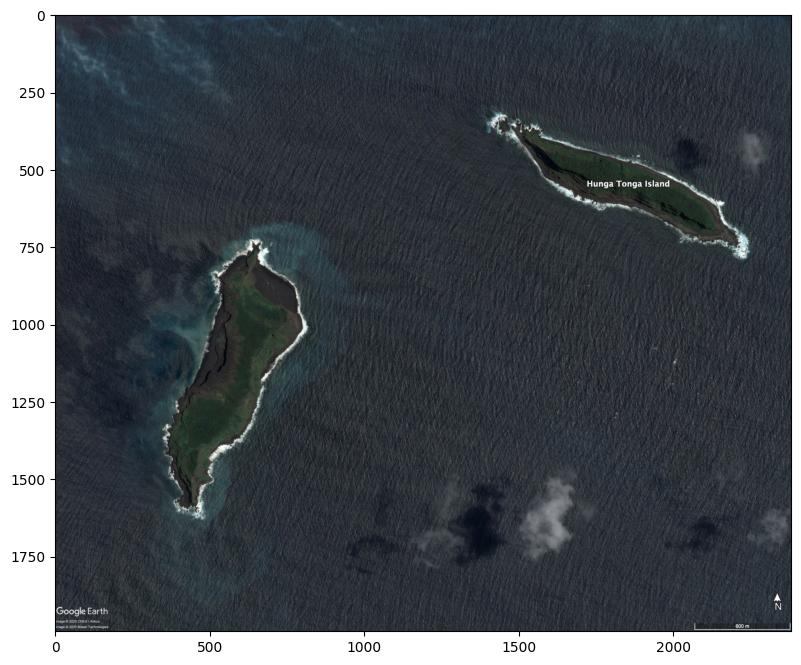

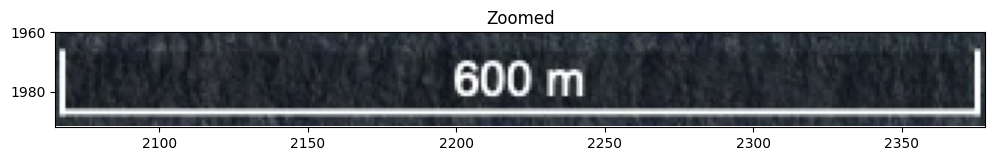

In [8]:
plt.figure(figsize=(12,8))
plt.imshow(image)
plt.show()

### zooming onto scale bar

plt.figure(figsize=(12,8))
plt.imshow(image)
plt.title("Zoomed")
plt.xlim(2065, 2378)   # adjusted to get the no. of pixels (313 -> 600 m)
plt.ylim(1992,1960)
plt.show()

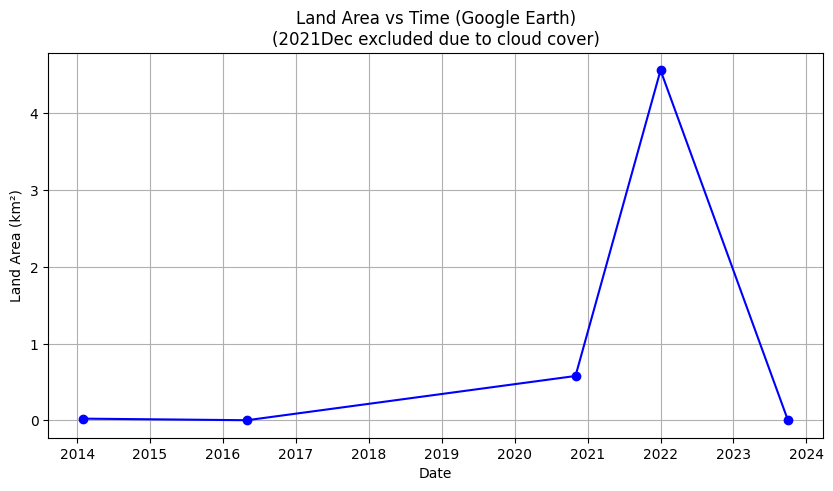

        Date  Land Area (km²)
0 2014-02-01         0.022415
1 2016-05-01         0.001837
2 2020-11-01         0.578387
3 2022-01-01         4.562790
4 2023-10-01         0.001837


In [9]:
images = [img for img in images if "2021Dec" not in img.name]

pixel_size = 600/313

dates, areas_km2 = [], []

for img_path in images:
    date = img_path.stem
    image = plt.imread(img_path)
    gray = np.mean(image, axis=2)# analogue for brightness of pixel

   # assuming land and water will have very different brightness
   # approximate measurement
    mask = gray < 0.5
    land_pixels = np.sum(mask)
    land_area_m2 = land_pixels*(pixel_size**2)

    dates.append(date)
    areas_km2.append(land_area_m2/1e4)

# converting dates so spacing in plot axis is correct
dates_dt = pd.to_datetime(dates, format="%Y%b")

plt.figure(figsize=(10,5))
plt.plot(dates_dt, areas_km2, marker='o', linestyle='-', color='blue')
plt.title("Land Area vs Time (Google Earth)\n(2021Dec excluded due to cloud cover)")
plt.xlabel("Date")
plt.ylabel("Land Area (km²)")
plt.grid(True)
plt.show()

df = pd.DataFrame({"Date": dates_dt, "Land Area (km²)": areas_km2})
print(df)
